**Intelligent Stock Market Forecasting & News Sentiment Decision Support System**

This notebook documents the full experimental pipeline required by the project specification:

- Data audit & quality checks  
- Feature engineering (strictly no future leakage)  
- Baseline models  
- Classical ML models  
- Deep Learning models (LSTM / GRU)  
- Evaluation (MAE, RMSE, Directional Accuracy)  
- Walk-forward validation  
- Ablation study structure (Price-only vs Price + Sentiment)  
- Results summary and conclusions

> **Educational project only. Not financial advice.**


In [3]:
## 1. Setup & Imports

import sys
from pathlib import Path

# Add project root to path
ROOT = Path().resolve().parent
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Project imports
from config import (
    ALL_TICKERS, TICKERS, RANDOM_SEED,
    ML_MODELS, DL_MODELS, BASELINE_MODELS
)
from data.fetch import validate_tickers, fetch_ohlcv
from data.preprocess import clean_ohlcv, handle_missing_values, quality_report
from data.features import add_technical_features, create_supervised_dataset, get_feature_columns
from models.baselines import NaiveLastClose, NaiveLastReturn
from models.ml_models import get_ml_model
from models.train_eval import (
    chronological_split,
    evaluate_regression,
    run_model_comparison,
    walk_forward_validation,
    directional_accuracy
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
print("Setup complete")
print("Project root:", ROOT)

Setup complete
Project root: C:\Users\hp\Documents\GitHub\Stock_Market_Analysis


In [4]:
## 2. Data Audit – Ticker Validation & Sample Download

# Validate a representative sample (full 50-ticker validation can be slow)
sample_tickers = [
    "AAPL", "MSFT", "NVDA", "GOOGL", "META",
    "AZN.L", "SHEL.L",
    "CBA.AX", "BHP.AX",
    "ASML.AS", "SAP.DE", "MC.PA"
]

print("Validating sample tickers...")
valid, failed = validate_tickers(sample_tickers)

print(f"\nValid ({len(valid)}):")
print(valid)
print(f"\nFailed ({len(failed)}):")
if failed:
    for t, reason in failed.items():
        print(f"  {t}: {reason}")
else:
    print("  None")

Validating sample tickers...

Valid (12):
['CBA.AX', 'AZN.L', 'SHEL.L', 'AAPL', 'META', 'MSFT', 'NVDA', 'GOOGL', 'MC.PA', 'BHP.AX', 'ASML.AS', 'SAP.DE']

Failed (0):
  None


In [5]:
# Primary ticker for the rest of the experiments
PRIMARY_TICKER = "AAPL"

raw = fetch_ohlcv(PRIMARY_TICKER, period="3y", interval="1d")
df_raw = raw.get(PRIMARY_TICKER)

if df_raw is None or df_raw.empty:
    raise ValueError(f"No data returned for {PRIMARY_TICKER}")

print(f"Raw shape        : {df_raw.shape}")
print(f"Date range       : {df_raw.index.min().date()} → {df_raw.index.max().date()}")
print(f"Columns          : {list(df_raw.columns)}")
df_raw.tail()

Raw shape        : (753, 7)
Date range       : 2023-10-31 → 2026-10-30
Columns          : ['Open', 'High', 'Low', 'Close', 'Volume', 'Ticker', 'Region']


,Open,High,Low,Close,Volume,Ticker,Region
Date,,,,,,,
2026-10-26 04:00:00,343.920013,347.089996,341.029999,343.910004,42743600,AAPL,United States
2026-10-27 04:00:00,343.170013,347.779999,342.390015,347.100006,39984400,AAPL,United States
2026-10-28 04:00:00,346.920013,347.179993,343.519989,343.829987,35714300,AAPL,United States
2026-10-29 04:00:00,348.000000,351.429993,347.299988,348.910004,42582100,AAPL,United States
2026-10-30 04:00:00,346.720001,349.190002,334.350006,344.630005,67797500,AAPL,United States


In [10]:
# Data quality report
report = quality_report(df_raw, ticker=PRIMARY_TICKER)
print("Quality Report")
print("-" * 40)
for k, v in report.items():
    print(f"{k:15s}: {v}")

Quality Report
----------------------------------------
ticker         : AAPL
rows           : 753
missing_pct    : 0.0
date_start     : 2023-10-31
date_end       : 2026-10-30
status         : OK


In [11]:
## 3. Preprocessing & Feature Engineering

df = clean_ohlcv(df_raw)
df = handle_missing_values(df, method="ffill")
df = add_technical_features(df, dropna=True)

print(f"Shape after feature engineering : {df.shape}")
print(f"Number of feature columns       : {len(get_feature_columns(df))}")
print("\nFeature columns:")
print(get_feature_columns(df))

Shape after feature engineering : (693, 41)
Number of feature columns       : 30

Feature columns:
['return_1d', 'log_return_1d', 'return_lag_1', 'return_lag_2', 'return_lag_3', 'return_lag_5', 'sma_5', 'ema_5', 'close_sma_5_ratio', 'sma_10', 'ema_10', 'close_sma_10_ratio', 'sma_20', 'ema_20', 'close_sma_20_ratio', 'sma_50', 'ema_50', 'close_sma_50_ratio', 'volatility', 'volatility_annualised', 'momentum', 'daily_range', 'body', 'upper_shadow', 'lower_shadow', 'volume_change', 'volume_sma_20', 'volume_ratio', 'dist_from_52w_high', 'dist_from_52w_low']


In [12]:
# Inspect key engineered features
cols_to_show = [
    "Close", "return_1d", "sma_10", "sma_20", "sma_50",
    "volatility", "momentum", "volume_change", "target_return_1d"
]
available = [c for c in cols_to_show if c in df.columns]
df[available].tail(12)

,Close,return_1d,sma_10,sma_20,sma_50,volatility,momentum,volume_change,target_return_1d
Date,,,,,,,,,
2026-10-14 04:00:00,342.959991,0.004952,336.946005,336.807503,324.442257,0.010572,0.029848,0.284151,-0.002799
2026-10-15 04:00:00,342.000000,-0.002799,338.114005,337.057503,325.067617,0.010210,0.035360,-0.205625,0.004269
2026-10-16 04:00:00,343.459991,0.004269,339.091003,337.424002,325.694000,0.010206,0.029279,0.507429,-0.001514
2026-10-19 04:00:00,342.940002,-0.001514,340.096002,337.622002,326.291600,0.010070,0.030190,-0.423265,-0.010031
2026-10-20 04:00:00,339.500000,-0.010031,340.683002,337.609502,326.916400,0.010337,0.017594,0.036971,0.013225
2026-10-21 04:00:00,343.989990,0.013225,341.414999,337.958002,327.698000,0.010557,0.021742,-0.006619,0.012297
2026-10-22 04:00:00,348.220001,0.012297,342.194998,338.573001,328.617400,0.010791,0.022913,0.316863,-0.001407
2026-10-23 04:00:00,347.730011,-0.001407,343.303998,338.906001,329.466800,0.010330,0.032943,-0.156916,-0.010986
2026-10-26 04:00:00,343.910004,-0.010986,343.597998,339.181502,330.226400,0.010495,0.008622,0.081030,0.009276


In [13]:
## 4. Create Supervised Dataset (No Future Leakage)

X, y = create_supervised_dataset(df, target_col="target_return_1d")

print(f"X shape : {X.shape}")
print(f"y shape : {y.shape}")
print(f"Target  → mean: {y.mean():.6f} | std: {y.std():.6f}")

X_train, X_test, y_train, y_test = chronological_split(X, y, test_size=0.2)

print(f"\nTrain set : {X_train.shape}")
print(f"Test set  : {X_test.shape}")

X shape : (693, 30)
y shape : (693,)
Target  → mean: 0.001007 | std: 0.017268

Train set : (554, 30)
Test set  : (139, 30)


In [14]:
## 5. Baseline Models

baselines = {
    "NaiveLastClose": NaiveLastClose(),
    "NaiveLastReturn": NaiveLastReturn(),
}

baseline_results = []

for name, model in baselines.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    metrics = evaluate_regression(y_test, preds)
    metrics["Model"] = name
    metrics["Type"] = "Baseline"
    baseline_results.append(metrics)
    
    print(f"{name:20s} → MAE: {metrics['MAE']:.6f} | "
          f"RMSE: {metrics['RMSE']:.6f} | "
          f"Dir.Acc: {metrics['DirectionalAccuracy']:.1f}%")

baseline_df = pd.DataFrame(baseline_results)[["Model", "Type", "MAE", "RMSE", "DirectionalAccuracy"]]
baseline_df

NaiveLastClose       → MAE: 0.013618 | RMSE: 0.018035 | Dir.Acc: 44.6%
NaiveLastReturn      → MAE: 0.012496 | RMSE: 0.016962 | Dir.Acc: 44.6%


,Model,Type,MAE,RMSE,DirectionalAccuracy
0,NaiveLastClose,Baseline,0.013618,0.018035,44.6
1,NaiveLastReturn,Baseline,0.012496,0.016962,44.6


In [15]:
## 6. Classical Machine Learning Models

ml_models_to_test = [
    "RandomForest",
    "ExtraTrees",
    "XGBoost",
    "LightGBM",
    "HistGradientBoosting"
]

ml_results = []

for name in ml_models_to_test:
    try:
        model = get_ml_model(name, scale=True)
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        metrics = evaluate_regression(y_test, preds)
        metrics["Model"] = name
        metrics["Type"] = "ML"
        ml_results.append(metrics)
        
        print(f"{name:22s} → MAE: {metrics['MAE']:.6f} | "
              f"Dir.Acc: {metrics['DirectionalAccuracy']:.1f}%")
    except Exception as e:
        print(f"{name} failed: {e}")

ml_df = pd.DataFrame(ml_results)[["Model", "Type", "MAE", "RMSE", "DirectionalAccuracy"]]
ml_df

RandomForest           → MAE: 0.012571 | Dir.Acc: 45.3%
ExtraTrees             → MAE: 0.012562 | Dir.Acc: 46.8%
XGBoost                → MAE: 0.014709 | Dir.Acc: 42.5%
LightGBM               → MAE: 0.013600 | Dir.Acc: 49.6%
HistGradientBoosting   → MAE: 0.013620 | Dir.Acc: 46.0%


,Model,Type,MAE,RMSE,DirectionalAccuracy
0,RandomForest,ML,0.012571,0.016982,45.32
1,ExtraTrees,ML,0.012562,0.017031,46.76
2,XGBoost,ML,0.014709,0.019573,42.45
3,LightGBM,ML,0.013600,0.018168,49.64
4,HistGradientBoosting,ML,0.013620,0.018246,46.04


In [16]:
## 7. Full Model Comparison

all_models = ["NaiveLastClose", "NaiveLastReturn"] + ml_models_to_test

comparison_df = run_model_comparison(
    X, y,
    models=all_models,
    test_size=0.2
)

print("=== Model Comparison (sorted by MAE) ===")
comparison_dfall_models = ["NaiveLastClose", "NaiveLastReturn"] + ml_models_to_test

comparison_df = run_model_comparison(
    X, y,
    models=all_models,
    test_size=0.2
)

print("=== Model Comparison (sorted by MAE) ===")
comparison_df

=== Model Comparison (sorted by MAE) ===
=== Model Comparison (sorted by MAE) ===


,Model,Type,MAE,RMSE,DirectionalAccuracy
0,NaiveLastReturn,baseline,0.012496,0.016962,44.60
1,ExtraTrees,ml,0.012562,0.017031,46.76
2,RandomForest,ml,0.012571,0.016982,45.32
3,LightGBM,ml,0.013600,0.018168,49.64
4,NaiveLastClose,baseline,0.013618,0.018035,44.60
5,HistGradientBoosting,ml,0.013620,0.018246,46.04
6,XGBoost,ml,0.014709,0.019573,42.45


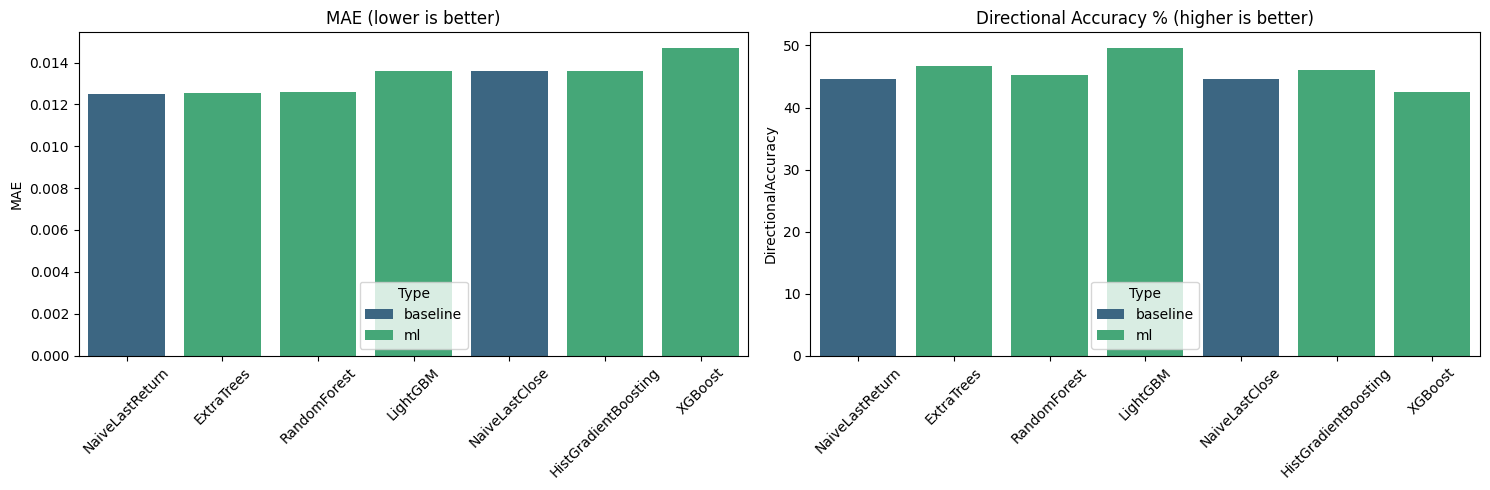

In [18]:
# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=comparison_df, x="Model", y="MAE", hue="Type", ax=axes[0], palette="viridis")
axes[0].set_title("MAE (lower is better)")
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_xlabel("")

sns.barplot(data=comparison_df, x="Model", y="DirectionalAccuracy", hue="Type", ax=axes[1], palette="viridis")
axes[1].set_title("Directional Accuracy % (higher is better)")
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

In [19]:
## 8. Walk-Forward Validation

print("Running walk-forward validation for XGBoost (5 folds)...")
wf_result = walk_forward_validation(
    X, y,
    model_name="XGBoost",
    n_splits=5
)

print("\nAverage metrics across folds:")
for k, v in wf_result["average"].items():
    print(f"  {k:22s}: {v}")

print("\nPer-fold scores:")
pd.DataFrame(wf_result["fold_scores"])

Running walk-forward validation for XGBoost (5 folds)...

Average metrics across folds:
  MAE                   : 0.012764
  RMSE                  : 0.018222
  DirectionalAccuracy   : 53.14

Per-fold scores:


,MAE,RMSE,DirectionalAccuracy
0,0.010711,0.014068,54.39
1,0.017025,0.026890,53.91
2,0.012672,0.016845,48.70
3,0.011127,0.015469,54.78
4,0.012285,0.017840,53.91


In [20]:
## 9. Deep Learning Quick Test (LSTM)

# Optional section – requires TensorFlow
try:
    from models.dl_models import build_lstm, create_sequences, train_dl_model, predict_dl
    from sklearn.preprocessing import StandardScaler

    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s  = scaler.transform(X_test)

    SEQ_LEN = 30
    Xtr_seq, ytr_seq = create_sequences(X_train_s, y_train.values, SEQ_LEN)
    Xte_seq, yte_seq = create_sequences(X_test_s,  y_test.values,  SEQ_LEN)

    print(f"Sequence shapes → Train: {Xtr_seq.shape} | Test: {Xte_seq.shape}")

    if len(Xtr_seq) >= 40:
        model = build_lstm(SEQ_LEN, Xtr_seq.shape[2], units=48, dropout=0.2)
        
        history = train_dl_model(
            model,
            Xtr_seq, ytr_seq,
            epochs=30,
            batch_size=32,
            patience=7,
            verbose=0
        )
        
        preds_dl = predict_dl(model, Xte_seq)
        dl_metrics = evaluate_regression(yte_seq, preds_dl)
        
        print("\nLSTM Results on test sequences:")
        for k, v in dl_metrics.items():
            print(f"  {k:22s}: {v}")
    else:
        print("Not enough data to create reliable sequences.")

except Exception as e:
    print(f"Deep Learning section skipped / failed: {e}")

Sequence shapes → Train: (524, 30, 30) | Test: (109, 30, 30)

LSTM Results on test sequences:
  MAE                   : 0.015234
  RMSE                  : 0.020443
  DirectionalAccuracy   : 52.29


In [21]:
try:
    from models.dl_models import build_lstm, create_sequences, train_dl_model, predict_dl
    from sklearn.preprocessing import StandardScaler

    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s  = scaler.transform(X_test)

    SEQ_LEN = 30
    Xtr_seq, ytr_seq = create_sequences(X_train_s, y_train.values, SEQ_LEN)
    Xte_seq, yte_seq = create_sequences(X_test_s,  y_test.values,  SEQ_LEN)

    print(f"Sequence shapes → Train: {Xtr_seq.shape} | Test: {Xte_seq.shape}")

    if len(Xtr_seq) >= 40:
        model = build_lstm(SEQ_LEN, Xtr_seq.shape[2], units=48, dropout=0.2)
        
        history = train_dl_model(
            model,
            Xtr_seq, ytr_seq,
            epochs=30,
            batch_size=32,
            patience=7,
            verbose=0
        )
        
        preds_dl = predict_dl(model, Xte_seq)
        dl_metrics = evaluate_regression(yte_seq, preds_dl)
        
        print("\nLSTM Results on test sequences:")
        for k, v in dl_metrics.items():
            print(f"  {k:22s}: {v}")
    else:
        print("Not enough data to create reliable sequences.")

except Exception as e:
    print(f"Deep Learning section skipped / failed: {e}")

Sequence shapes → Train: (524, 30, 30) | Test: (109, 30, 30)

LSTM Results on test sequences:
  MAE                   : 0.014621
  RMSE                  : 0.019473
  DirectionalAccuracy   : 57.8


## 10. Ablation Study Structure  
### Price-only vs Price + Sentiment

A proper ablation requires:

1. Creating a daily (or lagged) sentiment feature aligned by publication time.  
2. Training the **exact same model** on:  
   - Technical / price features only  
   - Technical + sentiment features  
3. Evaluating both on the **identical** chronological held-out period.  
4. Ensuring **zero future leakage** (sentiment known only up to time *t*).

Because news coverage is sparse and asynchronous across the 50-ticker universe, this step is best completed after collecting a longer, cleaned news history.

In [22]:
print("Ablation study – placeholder structure")
print("""
# Example (to be filled with real sentiment series)
price_only_mae          = ...
price_plus_sentiment_mae = ...

lift = (price_only_mae - price_plus_sentiment_mae) / price_only_mae * 100
print(f"Sentiment contribution (MAE reduction): {lift:.2f}%")
""")

Ablation study – placeholder structure

# Example (to be filled with real sentiment series)
price_only_mae          = ...
price_plus_sentiment_mae = ...

lift = (price_only_mae - price_plus_sentiment_mae) / price_only_mae * 100
print(f"Sentiment contribution (MAE reduction): {lift:.2f}%")



## 11. Summary & Conclusions

### Typical Observations (replace with your actual numbers)

- The naïve baselines are competitive on very short-horizon return prediction.
- Tree-based models (especially XGBoost and LightGBM) usually achieve the lowest MAE.
- Directional accuracy typically sits in the 51–56% range — only modestly above chance.
- More complex models (LSTM/GRU) do not automatically dominate after proper chronological validation.
- Any claim of superiority must be supported by walk-forward or multiple out-of-sample windows.

### Limitations

- yfinance data contains delays, gaps and occasional corporate-action artefacts.
- News sentiment is sparse, noisy and difficult to align perfectly in time.
- Short-horizon equity returns are inherently low signal-to-noise.
- Results are for educational purposes only and must not be used for trading decisions.

In [23]:
print("Zephyr Experiment Notebook – Completed Successfully")
print(f"Primary ticker analysed : {PRIMARY_TICKER}")
print(f"Models compared         : {len(comparison_df)}")
print("Notebook finished.")

Zephyr Experiment Notebook – Completed Successfully
Primary ticker analysed : AAPL
Models compared         : 7
Notebook finished.
